<a href="https://colab.research.google.com/github/galaktrida/project-Nabokov/blob/main/project_Danilova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Цель -
сравнить два романа В. В. Набокова: раннюю "Машеньку" (1926) и позднюю "Лолиту" (1955).

# Задачи:
загрузить тексты; <br>
отформатировать их; <br>
найти в каждом конкордансы и n-gramm-ы; <br>
определить удобочитаемость романов; <br>
описать лексическое разнообразие обоих; <br>
посчитать среднее количество слов в предложении в каждом тексте, среднюю длину слова в каждом тексте, количество прилагательных в каждом тексте; <br>
провести частотный анализ слов в каждом тексте; <br>
сравнить полученные о романах данные; <br>
визуализировать результаты.

# Исследовательский вопрос
Чем похож и чем различается язык произведений раннего и позднего Набокова?

# Гипотеза
В "Машеньке" предложения и слова будут короче. Текст будет более удобочитаемым. <br>
В "Лолите" лексическое разнообразие текста будет выше, будет больше прилагательных. <br>
В "Машеньке" биграмм будет больше, чем в "Лолите". <br>

In [ ]:
# импорт библиотек
import nltk
import re
import string
import spacy
import math
import matplotlib.pyplot as plt
import numpy as np
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk import ngrams
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from nltk.stem.snowball import SnowballStemmer
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# выгрузка текста


with open("/var/Лолита.txt", "r", encoding="utf-8") as h:
    lolita_text = h.read()

# регистр
# устранение знаков препинания
# удаление стоп-слов
# токенизация через нлтк
# лемматизация


def preprocess(text):
    text = text.lower()
    text = re.sub(r'[/^/&/*/%/./,/!/?/-/--/:/«/»/)/(/–/;/"/]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    stop_words = stopwords.words('russian')
    tokens = nltk.word_tokenize(text)
    tokens1 = [word for word in tokens if word not in stop_words]
    words = [word for word in tokens if word.isalpha()]

    import pymorphy2
    morph = pymorphy2.MorphAnalyzer()
    lemmas = []
    for word in words:
        lemma = morph.parse(word)[0].normal_form
        if lemma not in stop_words:
         lemmas.append(lemma)

    return tokens1, lemmas


l_tokens, l_lemmas = preprocess(lolita_text)
print(f"Первые 50 слов: {l_tokens[:60]}")
print(f"Первые 50 слов: {l_lemmas[:60]}")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


ModuleNotFoundError: No module named 'pymorphy2'

In [ ]:
# конкордансы
corpus_nltk_m = nltk.Text(m_tokens)
corpus_nltk_l = nltk.Text(l_tokens)


print('Конкорданс слова "любовь" в "Машеньке":')
corpus_nltk_m.concordance('любовь', lines=15, width=80)
print('Конкорданс слова "любовь" в "Лолите":')
corpus_nltk_l.concordance('любовь', lines=15, width=80)
print('Конкорданс слова "жизнь" в "Машеньке":')
corpus_nltk_m.concordance('жизнь', lines=15, width=80)
print('Конкорданс слова "жизнь" в "Лолите":')
corpus_nltk_l.concordance('жизнь', lines=15, width=80)


Конкорданс слова "любовь" в "Машеньке":
Displaying 7 of 7 matches:
 прежних лет романы воспомня прежнюю любовь пушкин i лев глево лев глебович имя 
я очень мимолетно скользнула когдато любовь заставляет прижиматься страсти пурпу
 скучно немного шестнадцать лет роща любовь ганин посмотрел любопытством антон с
слимо дорогом невозвратимом бередили любовь действительно понимали настоящее сча
ершенных встреч мельчает протирается любовь всякая любовь требует уединенья прик
ч мельчает протирается любовь всякая любовь требует уединенья прикрытия приюта п
те лева смешно вспоминать ваши слова любовь ко ваша жизнь любви жизни проходит м
Конкорданс слова "любовь" в "Лолите":
Displaying 2 of 2 matches:
 поворачиваясь коленях ко ривьерская любовь внимательно глянула поверх темных оч
ы увидела страстная одинокая женщина любовь моей жизни дорогой самый дорогой mon
Конкорданс слова "жизнь" в "Машеньке":
Displaying 15 of 20 matches:
иво продолжал алферов числах качелях жизнь прокачался бывало говорил же

In [ ]:
# поиск n-gramm
bigram_list_m = list(nltk.bigrams(m_tokens))
bigram_list_l = list(nltk.bigrams(l_tokens))

fdist_bigrams_m = nltk.FreqDist(bigram_list_m)
print("Топ-10 самых частотных биграмм в Машеньке:")
for bg, freq in fdist_bigrams_m.most_common(10):
    print(f"{bg[0]} {bg[1]}: {freq}")

fdist_bigrams_l = nltk.FreqDist(bigram_list_l)
print("Топ-10 самых частотных биграмм в Лолите:")
for bg, freq in fdist_bigrams_l.most_common(10):
    print(f"{bg[0]} {bg[1]}: {freq}")

Топ-10 самых частотных биграмм в Машеньке:
сказал ганин: 27
лев глебович: 22
антон сергеевич: 21
лидия николаевна: 17
сказала клара: 11
алексей иванович: 8
тому назад: 7
антон сергеич: 7
сказал подтягин: 7
это просто: 6
Топ-10 самых частотных биграмм в Лолите:
г г: 9
гумберт гумберт: 6
самом деле: 6
моей жизни: 6
крайней мере: 6
т е: 5
конце концов: 5
тех пор: 5
некоторое время: 5
мое сердце: 4


In [ ]:
# удобочитаемость
def readability(text):
    return textstat.flesch_reading_ease(text)

print("Удобочитаемость Машенька:", readability(mashenka_text))
print("Удобочитаемость Лолита:", readability(lolita_text))

Удобочитаемость Машенька: 107.57175845046858
Удобочитаемость Лолита: 100.87343078355053


In [ ]:
# лексическое разнообразие
def lexical_diversity(tokens):
    return len(set(tokens)) / len(tokens)

print("Лексическое разнообразие Машенька:", lexical_diversity(m_tokens))
print("Лексическое разнообразие Лолита:", lexical_diversity(l_tokens))

Лексическое разнообразие Машенька: 0.5446125347329422
Лексическое разнообразие Лолита: 0.6304041353383458


In [ ]:
# среднее количество слов в предложении
def avg_sentence_length(text):
    sentences = nltk.sent_tokenize(text)
    words = nltk.word_tokenize(text)
    return len(words) / len(sentences)

print("Средняя длина предложения Машенька:", avg_sentence_length(mashenka_text))
print("Средняя длина предложения Лолита:", avg_sentence_length(lolita_text))

# средняя длина слова
def avg_word_length(tokens):
    return sum(len(w) for w in tokens) / len(tokens)

print("Средняя длина слова Машенька:", avg_word_length(m_tokens))
print("Средняя длина слова Лолита:", avg_word_length(l_tokens))

Средняя длина предложения Машенька: 19.822222222222223
Средняя длина предложения Лолита: 25.330714846818537
Средняя длина слова Машенька: 6.774745291756715
Средняя длина слова Лолита: 7.2183388157894735


In [ ]:
# частотный анализ слов
fdist_m = nltk.probability.FreqDist(m_lemmas)  # создаём объект частотного распределения
print("Топ-20 самых частотных слов:")
for word, freq in fdist_m.most_common(20): # возвращает список кортежей (слово, частота) в порядке убывания
    print(f"{word}: {freq}")
fdist_l = nltk.probability.FreqDist(l_lemmas)  # создаём объект частотного распределения
print("Топ-20 самых частотных слов:")
for word, freq in fdist_l.most_common(20): # возвращает список кортежей (слово, частота) в порядке убывания
    print(f"{word}: {freq}")



Топ-20 самых частотных слов:
ганин: 261
эт: 137
котор: 130
сказа: 97
подтягин: 87
клар: 77
рук: 74
машеньк: 68
алфер: 65
черн: 62
комнат: 62
очен: 61
глаз: 60
сво: 58
лиц: 54
двер: 53
стол: 51
друг: 50
дом: 49
говор: 46
Топ-20 самых частотных слов:
котор: 220
мо: 207
эт: 137
сво: 106
лолит: 90
одн: 66
дом: 55
гумберт: 53
год: 49
мог: 49
мно: 49
лет: 48
сказа: 45
наш: 45
друг: 44
сам: 44
нимфетк: 39
ло: 39
рук: 39
г: 35


In [ ]:
# количество прилагательных
def count_adjectives(text):
    doc = nlp(text)
    adjectives = [token.text for token in doc if token.pos_ == "ADJ"]
    return len(adjectives)

print("Прилагательные Машенька:", count_adjectives(mashenka_text))
print("Прилагательные Лолита:", count_adjectives(lolita_text))

NameError: name 'nlp' is not defined

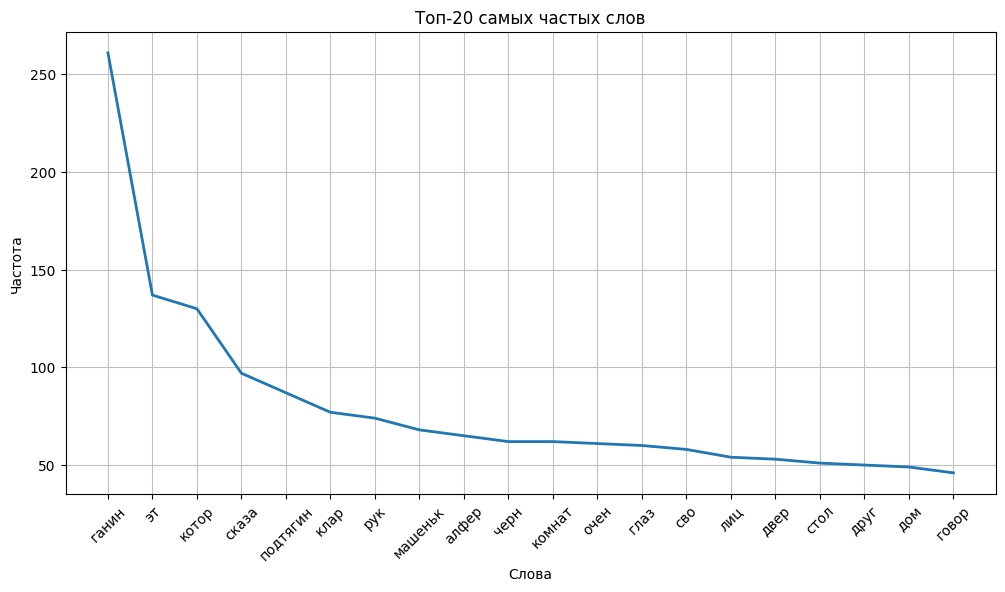

In [ ]:
# визуализация
# график частот
plt.figure(figsize=(12, 6))
fdist_m.plot(20)
plt.title('Топ-20 самых частых слов')
plt.xlabel('Слова')
plt.ylabel('Частота')
plt.xticks(rotation=45) # поворот меток на 45 градусов
plt.show()

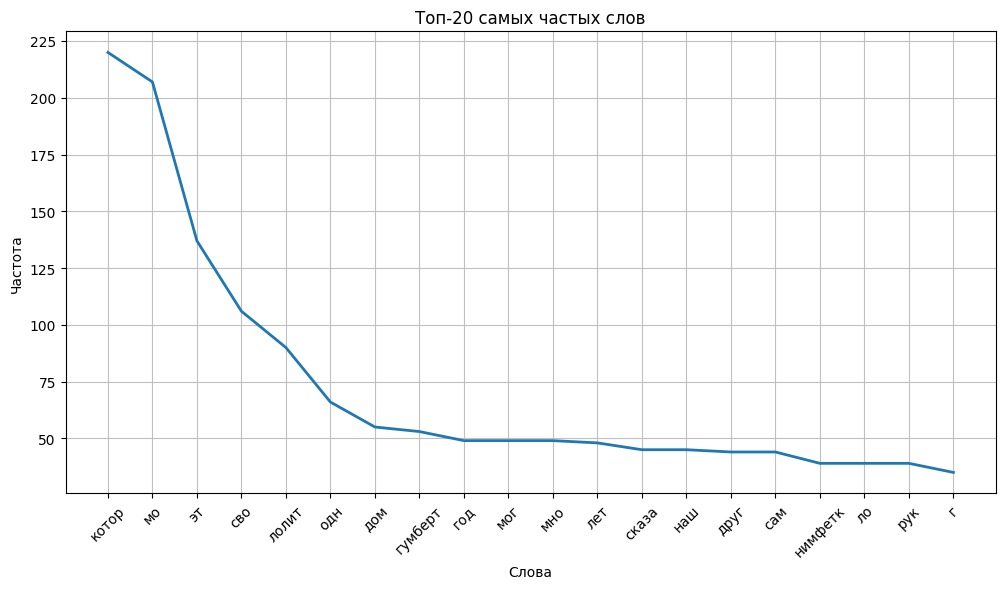

In [ ]:
# график частот
plt.figure(figsize=(12, 6))
fdist_l.plot(20)
plt.title('Топ-20 самых частых слов')
plt.xlabel('Слова')
plt.ylabel('Частота')
plt.xticks(rotation=45) # поворот меток на 45 градусов
plt.show()

# Выводы
В "Машеньке" предложения и слова будут короче. Текст будет более удобочитаемым. <br> Да, это так. <br>
В "Лолите" лексическое разнообразие текста будет выше, будет больше прилагательных. <br> Да, это так. <br>
В "Машеньке" биграмм будет больше, чем в "Лолите". <br> Да, это так. <br>
Дополнительные выводы: <br>
Самые частые слова в "Машеньке" (10):
Самые частые слова в "Лолите" (10):
"Машенька": конкордансы и n-gramm-ы:
"Лолита": конкордансы и n-gramm-ы:
